# Plotly Dashboard

---

## 1. Data Wrangling
## Cleaning and Preprocessing of Datasets

In [26]:
# Immport libraries
import pandas as pd
import numpy as np

In [27]:
# Import datasets (modify accordingly)

Simple function to inspect the datasets

In [28]:
def inspect_dataset(df, name):
    print("\nShape:")      # Dataset shape
    print(df.shape)

    print("\nColumns:")    # Column names
    print(df.columns.tolist())

    print("\nData Types:")  # Data types
    print(df.dtypes)

    print("\nMissing Values:")  # No. of missing values 
    print(df.isnull().sum())

    print("\nDuplicate Rows:")  # No. of duplicate rows
    print(df.duplicated().sum())

    print("\nFirst 5 Rows:")   # Display first 5 rows
    display(df.head())

In [29]:
inspect_dataset(profiles, "Client Profiles")


Shape:
(148, 8)

Columns:
['CLIENT ID', 'TYPE', 'SG-BASED', 'OVERSEAS', 'COUNTRY OF OVERSEAS CLIENT', 'COMMENCEMENT DATE', 'STAFF STRENGTH', 'SECTOR']

Data Types:
CLIENT ID                     object
TYPE                          object
SG-BASED                      object
OVERSEAS                      object
COUNTRY OF OVERSEAS CLIENT    object
COMMENCEMENT DATE             object
STAFF STRENGTH                object
SECTOR                        object
dtype: object

Missing Values:
CLIENT ID                       0
TYPE                            0
SG-BASED                       21
OVERSEAS                      114
COUNTRY OF OVERSEAS CLIENT     79
COMMENCEMENT DATE               0
STAFF STRENGTH                  0
SECTOR                          0
dtype: int64

Duplicate Rows:
0

First 5 Rows:


,CLIENT ID,TYPE,SG-BASED,OVERSEAS,COUNTRY OF OVERSEAS CLIENT,COMMENCEMENT DATE,STAFF STRENGTH,SECTOR
0,G1-001,Govt,Yes,NaN,,2020-01-19 00:00:00,More than 200,Finance
1,G1-002,Govt,Yes,NaN,,2020-05-19 00:00:00,More than 200,Security
2,G1-003,Govt,Yes,NaN,,2021-07-18 00:00:00,> 200,Transportation
3,G1-005,Govt,Y,NaN,NaN,2022-02-11 00:00:00,> 200,Security
4,G1-006,Govt,Y,NaN,NaN,2022-03-18 00:00:00,50 ~ 200,Legal


In [30]:
inspect_dataset(survey, "Client Survey")


Shape:
(432, 7)

Columns:
['YEAR', 'CLIENT ID', 'PRESALES AND PARTNERSHIP', 'TECHNICAL EXPERTISE', 'PROJECT DELIVERY', 'POST-SALES SUPPORT', 'NPS RATING']

Data Types:
YEAR                         int64
CLIENT ID                   object
PRESALES AND PARTNERSHIP     int64
TECHNICAL EXPERTISE          int64
PROJECT DELIVERY             int64
POST-SALES SUPPORT           int64
NPS RATING                   int64
dtype: object

Missing Values:
YEAR                        0
CLIENT ID                   0
PRESALES AND PARTNERSHIP    0
TECHNICAL EXPERTISE         0
PROJECT DELIVERY            0
POST-SALES SUPPORT          0
NPS RATING                  0
dtype: int64

Duplicate Rows:
30

First 5 Rows:


,YEAR,CLIENT ID,PRESALES AND PARTNERSHIP,TECHNICAL EXPERTISE,PROJECT DELIVERY,POST-SALES SUPPORT,NPS RATING
0,2021,G1-001,3,4,4,5,8
1,2021,G1-002,3,4,4,2,7
2,2021,G1-003,5,4,3,5,8
3,2021,G1-001,3,4,4,5,8
4,2021,G1-002,3,4,4,2,7


In [31]:
inspect_dataset(finance, "Revenue and COGS")


Shape:
(423, 6)

Columns:
['CLIENT ID', 'YEAR', 'REVENUE', 'HARDWARE', 'SOFTWARE', 'MANPOWER']

Data Types:
CLIENT ID    object
YEAR          int64
REVENUE       int64
HARDWARE      int64
SOFTWARE      int64
MANPOWER      int64
dtype: object

Missing Values:
CLIENT ID    0
YEAR         0
REVENUE      0
HARDWARE     0
SOFTWARE     0
MANPOWER     0
dtype: int64

Duplicate Rows:
21

First 5 Rows:


,CLIENT ID,YEAR,REVENUE,HARDWARE,SOFTWARE,MANPOWER
0,G1-001,2021,148180,17321,25562,41201
1,G1-001,2022,197313,23604,32875,50085
2,G1-001,2023,349899,51332,71695,89089
3,G1-001,2024,268821,40969,56452,76545
4,G1-001,2025,138115,14516,20889,28968


### Client survey score range
This check ensures that the values are in the correct ranges for each column (1-5 for most columns, 0-10 for NPS rating)

In [32]:
rating_cols = [
    "PRESALES AND PARTNERSHIP",
    "TECHNICAL EXPERTISE",
    "PROJECT DELIVERY",
    "POST-SALES SUPPORT",
    "NPS RATING"
]

survey[rating_cols].agg(["min", "max"])

,PRESALES AND PARTNERSHIP,TECHNICAL EXPERTISE,PROJECT DELIVERY,POST-SALES SUPPORT,NPS RATING
min,1,2,1,1,4
max,5,5,5,5,10


The numbers are within the specified ranges given in the meta data, no extra modification required.

### Client revenue range
This check ensures that the values (especially revenue) are valid e.g. not negative

In [33]:
finance.describe()

,YEAR,REVENUE,HARDWARE,SOFTWARE,MANPOWER
count,423.000000,4.230000e+02,423.000000,423.000000,423.000000
mean,2023.716312,3.439590e+05,40519.000000,68901.973995,82697.349882
std,1.233380,2.809012e+05,36653.715911,59477.106553,71582.083635
min,2021.000000,1.109600e+04,1026.000000,2834.000000,2285.000000
25%,2023.000000,1.392325e+05,13101.000000,24251.500000,33097.500000
50%,2024.000000,2.626530e+05,26576.000000,48236.000000,64751.000000
75%,2025.000000,4.893005e+05,58281.000000,102300.500000,111545.500000
max,2025.000000,1.778495e+06,173659.000000,348093.000000,673359.000000


### Duplicate rows
This section is to resolve the duplicate rows from the "Client Survey" and "Revenue and COGS" datasets.

In [34]:
survey_duplicates = survey[survey.duplicated(keep=False)]

survey_duplicates.sort_values(["CLIENT ID", "YEAR"]).head(20)

,YEAR,CLIENT ID,PRESALES AND PARTNERSHIP,TECHNICAL EXPERTISE,PROJECT DELIVERY,POST-SALES SUPPORT,NPS RATING
0,2021,G1-001,3,4,4,5,8
3,2021,G1-001,3,4,4,5,8
33,2022,G1-001,5,5,3,4,9
37,2022,G1-001,5,5,3,4,9
80,2023,G1-001,5,4,3,4,7
88,2023,G1-001,5,4,3,4,7
164,2024,G1-001,5,5,3,4,8
179,2024,G1-001,5,5,3,4,8
1,2021,G1-002,3,4,4,2,7
4,2021,G1-002,3,4,4,2,7


In [35]:
finance_duplicates = finance[finance.duplicated(keep=False)]

finance_duplicates.sort_values(["CLIENT ID", "YEAR"]).head(20)

,CLIENT ID,YEAR,REVENUE,HARDWARE,SOFTWARE,MANPOWER
27,G1-010,2023,302802,38429,58676,109502
28,G1-010,2023,302802,38429,58676,109502
29,G1-010,2024,336405,49777,65314,76727
30,G1-010,2024,336405,49777,65314,76727
31,G1-010,2025,737373,89810,134715,253187
32,G1-010,2025,737373,89810,134715,253187
57,N1-001,2021,62351,11844,16111,21089
58,N1-001,2021,62351,11844,16111,21089
72,N1-004,2023,28123,5525,7284,6309
73,N1-004,2023,28123,5525,7284,6309


These rows are exact duplicates, providing no extra value towards an accurate analysis of the datasets and can be dropped.

In [36]:
survey = survey.drop_duplicates().reset_index(drop=True)

In [37]:
finance = finance.drop_duplicates().reset_index(drop=True)

In [38]:
# Verify duplicate drop was successful
print("Survey duplicates:", survey.duplicated().sum())
print("Finance duplicates:", finance.duplicated().sum())

Survey duplicates: 0
Finance duplicates: 0


### Client Profiles
There are a few issues that can be identified from the inital inspection of the "client profiles" dataset. This section is to resolve the following issues:
- Date format
- Standardisation of columns
- Blank strings
- Missing values

#### Date format
commencement date is converted from object to datetime64[ns] 

In [39]:
profiles["COMMENCEMENT DATE"] = pd.to_datetime(
    profiles["COMMENCEMENT DATE"]
)

In [40]:
# Verify changes
profiles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   CLIENT ID                   148 non-null    object        
 1   TYPE                        148 non-null    object        
 2   SG-BASED                    127 non-null    object        
 3   OVERSEAS                    34 non-null     object        
 4   COUNTRY OF OVERSEAS CLIENT  69 non-null     object        
 5   COMMENCEMENT DATE           148 non-null    datetime64[ns]
 6   STAFF STRENGTH              148 non-null    object        
 7   SECTOR                      148 non-null    object        
dtypes: datetime64[ns](1), object(7)
memory usage: 9.4+ KB


In [41]:
# Inspect unique values of all columns
for col in profiles.columns:
    print(f"\n===== {col} =====")
    print(profiles[col].value_counts(dropna=False))


===== CLIENT ID =====
CLIENT ID
G1-001    1
P2-003    1
P2-005    1
P2-006    1
P2-007    1
         ..
P1-016    1
P1-017    1
P1-019    1
P1-020    1
P3-031    1
Name: count, Length: 148, dtype: int64

===== TYPE =====
TYPE
Private    113
Govt        22
NPO         13
Name: count, dtype: int64

===== SG-BASED =====
SG-BASED
Y      95
NaN    21
Yes    19
       13
Name: count, dtype: int64

===== OVERSEAS =====
OVERSEAS
NaN    114
Y       23
Yes     11
Name: count, dtype: int64

===== COUNTRY OF OVERSEAS CLIENT =====
COUNTRY OF OVERSEAS CLIENT
NaN            79
               35
Malaysia       14
Indonesia       8
China           5
India           4
Philippines     2
Malaysian       1
Name: count, dtype: int64

===== COMMENCEMENT DATE =====
COMMENCEMENT DATE
2024-01-16    2
2023-07-16    2
2019-04-18    2
2025-01-14    2
2024-06-16    2
             ..
2021-04-18    1
2021-04-01    1
2020-09-19    1
2020-07-19    1
2025-07-14    1
Name: count, Length: 141, dtype: int64

===== STAFF S

#### Standardisation of columns and missing values
The SG-based and overseas columns are mutually exclusive and should be Y or blank. The country of overseas client column should only be filled if the client is overseas.

In [42]:
# Standardising variations of "Y" and blank values 
profiles["SG-BASED"] = (
    profiles["SG-BASED"]
    .replace(r'^\s*$', np.nan, regex=True)
    .replace({"Yes": "Y"})
)

profiles["OVERSEAS"] = (
    profiles["OVERSEAS"]
    .replace(r'^\s*$', np.nan, regex=True)
    .replace({"Yes": "Y"})
)

profiles["COUNTRY OF OVERSEAS CLIENT"] = (
    profiles["COUNTRY OF OVERSEAS CLIENT"]
    .replace(r'^\s*$', np.nan, regex=True)
    .replace({"Malaysian": "Malaysia"})     # One outlier value, assumed to have the same meaning as country "Malaysia"
)

In [43]:
# Verify changes
for col in profiles.columns:
    print(f"\n===== {col} =====")
    print(profiles[col].value_counts(dropna=False))


===== CLIENT ID =====
CLIENT ID
G1-001    1
P2-003    1
P2-005    1
P2-006    1
P2-007    1
         ..
P1-016    1
P1-017    1
P1-019    1
P1-020    1
P3-031    1
Name: count, Length: 148, dtype: int64

===== TYPE =====
TYPE
Private    113
Govt        22
NPO         13
Name: count, dtype: int64

===== SG-BASED =====
SG-BASED
Y      114
NaN     34
Name: count, dtype: int64

===== OVERSEAS =====
OVERSEAS
NaN    114
Y       34
Name: count, dtype: int64

===== COUNTRY OF OVERSEAS CLIENT =====
COUNTRY OF OVERSEAS CLIENT
NaN            114
Malaysia        15
Indonesia        8
China            5
India            4
Philippines      2
Name: count, dtype: int64

===== COMMENCEMENT DATE =====
COMMENCEMENT DATE
2024-01-16    2
2023-07-16    2
2019-04-18    2
2025-01-14    2
2024-06-16    2
             ..
2021-04-18    1
2021-04-01    1
2020-09-19    1
2020-07-19    1
2025-07-14    1
Name: count, Length: 141, dtype: int64

===== STAFF STRENGTH =====
STAFF STRENGTH
> 200            59
50 ~ 200  

This follows the meta data context mentioned earlier. The columns are either Y or blank.

In [44]:
profiles[profiles["OVERSEAS"] == "Y"]

,CLIENT ID,TYPE,SG-BASED,OVERSEAS,COUNTRY OF OVERSEAS CLIENT,COMMENCEMENT DATE,STAFF STRENGTH,SECTOR
19,G2-001,Govt,NaN,Y,Indonesia,2022-01-08,> 200,Healthcare
20,G2-002,Govt,NaN,Y,Malaysia,2024-01-16,50 ~ 200,Education
21,G2-003,Govt,NaN,Y,Indonesia,2025-03-25,> 200,Healthcare
117,P3-001,Private,NaN,Y,Malaysia,2019-01-09,Less than 200,Healthcare
118,P3-002,Private,NaN,Y,India,2019-04-08,Less than 200,Healthcare
119,P3-003,Private,NaN,Y,Indonesia,2019-04-18,Less than 200,Manufacturing
120,P3-004,Private,NaN,Y,Malaysia,2019-05-19,Less than 200,Info Tech
121,P3-005,Private,NaN,Y,Malaysia,2019-08-18,Less than 200,Manufacturing
122,P3-006,Private,NaN,Y,Malaysia,2019-10-17,Less than 200,Manufacturing
123,P3-007,Private,NaN,Y,Malaysia,2020-01-18,> 200,Info Tech


This validates the relationships between the 3 columns. "SG-BASED" and "OVERSEAS" are mutually exclusive and the country is only stated if the client is overseas.

Next, the staff strength is standardised to the range format e.g. 1 ~ 49

In [45]:
profiles["STAFF STRENGTH"] = profiles["STAFF STRENGTH"].replace({
    "Less than 49": "1 ~ 49",
    "More than 200": "> 200"
})

for this case, "less than 200" is assumed to mean 50 ~ 200.

In [46]:
profiles["STAFF STRENGTH"] = profiles["STAFF STRENGTH"].replace({
    "Less than 200": "50 ~ 200"
})

In [47]:
# Verify changes
for col in profiles.columns:
    print(f"\n===== {col} =====")
    print(profiles[col].value_counts(dropna=False))


===== CLIENT ID =====
CLIENT ID
G1-001    1
P2-003    1
P2-005    1
P2-006    1
P2-007    1
         ..
P1-016    1
P1-017    1
P1-019    1
P1-020    1
P3-031    1
Name: count, Length: 148, dtype: int64

===== TYPE =====
TYPE
Private    113
Govt        22
NPO         13
Name: count, dtype: int64

===== SG-BASED =====
SG-BASED
Y      114
NaN     34
Name: count, dtype: int64

===== OVERSEAS =====
OVERSEAS
NaN    114
Y       34
Name: count, dtype: int64

===== COUNTRY OF OVERSEAS CLIENT =====
COUNTRY OF OVERSEAS CLIENT
NaN            114
Malaysia        15
Indonesia        8
China            5
India            4
Philippines      2
Name: count, dtype: int64

===== COMMENCEMENT DATE =====
COMMENCEMENT DATE
2024-01-16    2
2023-07-16    2
2019-04-18    2
2025-01-14    2
2024-06-16    2
             ..
2021-04-18    1
2021-04-01    1
2020-09-19    1
2020-07-19    1
2025-07-14    1
Name: count, Length: 141, dtype: int64

===== STAFF STRENGTH =====
STAFF STRENGTH
50 ~ 200    64
> 200       62


#### Final inspection before merge:

In [48]:
inspect_dataset(profiles, "Client Profiles")


Shape:
(148, 8)

Columns:
['CLIENT ID', 'TYPE', 'SG-BASED', 'OVERSEAS', 'COUNTRY OF OVERSEAS CLIENT', 'COMMENCEMENT DATE', 'STAFF STRENGTH', 'SECTOR']

Data Types:
CLIENT ID                             object
TYPE                                  object
SG-BASED                              object
OVERSEAS                              object
COUNTRY OF OVERSEAS CLIENT            object
COMMENCEMENT DATE             datetime64[ns]
STAFF STRENGTH                        object
SECTOR                                object
dtype: object

Missing Values:
CLIENT ID                       0
TYPE                            0
SG-BASED                       34
OVERSEAS                      114
COUNTRY OF OVERSEAS CLIENT    114
COMMENCEMENT DATE               0
STAFF STRENGTH                  0
SECTOR                          0
dtype: int64

Duplicate Rows:
0

First 5 Rows:


,CLIENT ID,TYPE,SG-BASED,OVERSEAS,COUNTRY OF OVERSEAS CLIENT,COMMENCEMENT DATE,STAFF STRENGTH,SECTOR
0,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance
1,G1-002,Govt,Y,NaN,NaN,2020-05-19,> 200,Security
2,G1-003,Govt,Y,NaN,NaN,2021-07-18,> 200,Transportation
3,G1-005,Govt,Y,NaN,NaN,2022-02-11,> 200,Security
4,G1-006,Govt,Y,NaN,NaN,2022-03-18,50 ~ 200,Legal


In [49]:
inspect_dataset(survey, "Client Survey")


Shape:
(402, 7)

Columns:
['YEAR', 'CLIENT ID', 'PRESALES AND PARTNERSHIP', 'TECHNICAL EXPERTISE', 'PROJECT DELIVERY', 'POST-SALES SUPPORT', 'NPS RATING']

Data Types:
YEAR                         int64
CLIENT ID                   object
PRESALES AND PARTNERSHIP     int64
TECHNICAL EXPERTISE          int64
PROJECT DELIVERY             int64
POST-SALES SUPPORT           int64
NPS RATING                   int64
dtype: object

Missing Values:
YEAR                        0
CLIENT ID                   0
PRESALES AND PARTNERSHIP    0
TECHNICAL EXPERTISE         0
PROJECT DELIVERY            0
POST-SALES SUPPORT          0
NPS RATING                  0
dtype: int64

Duplicate Rows:
0

First 5 Rows:


,YEAR,CLIENT ID,PRESALES AND PARTNERSHIP,TECHNICAL EXPERTISE,PROJECT DELIVERY,POST-SALES SUPPORT,NPS RATING
0,2021,G1-001,3,4,4,5,8
1,2021,G1-002,3,4,4,2,7
2,2021,G1-003,5,4,3,5,8
3,2021,N1-001,4,4,4,3,8
4,2021,N1-002,5,3,4,3,7


In [50]:
inspect_dataset(finance, "Revenue and COGS")


Shape:
(402, 6)

Columns:
['CLIENT ID', 'YEAR', 'REVENUE', 'HARDWARE', 'SOFTWARE', 'MANPOWER']

Data Types:
CLIENT ID    object
YEAR          int64
REVENUE       int64
HARDWARE      int64
SOFTWARE      int64
MANPOWER      int64
dtype: object

Missing Values:
CLIENT ID    0
YEAR         0
REVENUE      0
HARDWARE     0
SOFTWARE     0
MANPOWER     0
dtype: int64

Duplicate Rows:
0

First 5 Rows:


,CLIENT ID,YEAR,REVENUE,HARDWARE,SOFTWARE,MANPOWER
0,G1-001,2021,148180,17321,25562,41201
1,G1-001,2022,197313,23604,32875,50085
2,G1-001,2023,349899,51332,71695,89089
3,G1-001,2024,268821,40969,56452,76545
4,G1-001,2025,138115,14516,20889,28968


## Merging of Datasets
The cleaned datasets are merged to create the master dataset for use in the next part of data analysis.

The client profiles dataset is first merged with the finance dataset using the left join method which will keep multiple records of the same client according to the different years.

In [51]:
# Merge the profiles to the finances using the left join format
merged = profiles.merge(
    finance,
    on="CLIENT ID",
    how="left"
)

In [52]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   CLIENT ID                   400 non-null    object        
 1   TYPE                        400 non-null    object        
 2   SG-BASED                    295 non-null    object        
 3   OVERSEAS                    105 non-null    object        
 4   COUNTRY OF OVERSEAS CLIENT  105 non-null    object        
 5   COMMENCEMENT DATE           400 non-null    datetime64[ns]
 6   STAFF STRENGTH              400 non-null    object        
 7   SECTOR                      400 non-null    object        
 8   YEAR                        392 non-null    float64       
 9   REVENUE                     392 non-null    float64       
 10  HARDWARE                    392 non-null    float64       
 11  SOFTWARE                    392 non-null    float64       

There are two records in the finance dataset which do not have corresponding client IDs in the profile dataset. Since those clients have no recorded profile infomation the two records are ommitted from further imputation.

The survey dataset can then be merged according to the corresponding client and year.

In [53]:
# Merge with survey according to client ID and year
merged = merged.merge(
    survey,
    on=["CLIENT ID", "YEAR"],
    how="left"
)

In [54]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   CLIENT ID                   400 non-null    object        
 1   TYPE                        400 non-null    object        
 2   SG-BASED                    295 non-null    object        
 3   OVERSEAS                    105 non-null    object        
 4   COUNTRY OF OVERSEAS CLIENT  105 non-null    object        
 5   COMMENCEMENT DATE           400 non-null    datetime64[ns]
 6   STAFF STRENGTH              400 non-null    object        
 7   SECTOR                      400 non-null    object        
 8   YEAR                        392 non-null    float64       
 9   REVENUE                     392 non-null    float64       
 10  HARDWARE                    392 non-null    float64       
 11  SOFTWARE                    392 non-null    float64       

There are 8 missing records for the years of some client IDs, indicating that these clients have no records for some years.

In [55]:
# Check rows with missing records
merged[merged["YEAR"].isna()][
    ["CLIENT ID", "TYPE", "COMMENCEMENT DATE"]
]

,CLIENT ID,TYPE,COMMENCEMENT DATE
15,G1-005,Govt,2022-02-11
158,P1-017,Private,2023-01-09
210,P1-039,Private,2024-02-16
213,P1-041,Private,2024-03-21
239,P1-058,Private,2025-09-01
240,P1-059,Private,2025-09-25
278,P2-012,Private,2024-01-16
357,P3-013,Private,2022-05-02


In [56]:
# Verify that there is no record in the original finance dataset
finance[finance["CLIENT ID"] == "G1-005"]

,CLIENT ID,YEAR,REVENUE,HARDWARE,SOFTWARE,MANPOWER


Although these records have missing values for the finance and survey portions of the dataset, they can still provide useful data with the client profiles. Hence, these rows are retained in the final dataset.

## Creating Derived Columns
New columns will be derived from the existing columns according to the specifics in the meta data.

Derived columns based on finance columns

In [57]:
# Total cost of goods sold (COGS)
merged["COGS"] = (
    merged["HARDWARE"] +
    merged["SOFTWARE"] +
    merged["MANPOWER"]
)

# Gross profit
merged["GROSS PROFIT"] = (
    merged["REVENUE"] -
    merged["COGS"]
)

# Gross markup (%)
merged["GROSS MARKUP %"] = (
    merged["GROSS PROFIT"] / merged["COGS"]
) * 100

# Gross margin (%)
merged["GROSS MARGIN %"] = (
    merged["GROSS PROFIT"] / merged["REVENUE"]
) * 100

# Round values
merged["GROSS MARKUP %"] = merged["GROSS MARKUP %"].round(2)
merged["GROSS MARGIN %"] = merged["GROSS MARGIN %"].round(2)

Derived columns based on survey columns

In [58]:
# NPS rating categorisation 
merged["NPS CATEGORY"] = np.select(
    [
        merged["NPS RATING"].between(9, 10),
        merged["NPS RATING"].between(7, 8),
        merged["NPS RATING"].between(0, 6)
    ],
    [
        "Promoter",
        "Passive",
        "Detractor"
    ],
    default=np.nan
)

In [59]:
# verify changes
merged.head()

,CLIENT ID,TYPE,SG-BASED,OVERSEAS,COUNTRY OF OVERSEAS CLIENT,COMMENCEMENT DATE,STAFF STRENGTH,SECTOR,YEAR,REVENUE,...,PRESALES AND PARTNERSHIP,TECHNICAL EXPERTISE,PROJECT DELIVERY,POST-SALES SUPPORT,NPS RATING,COGS,GROSS PROFIT,GROSS MARKUP %,GROSS MARGIN %,NPS CATEGORY
0,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2021.0,148180.0,...,3.0,4.0,4.0,5.0,8.0,84084.0,64096.0,76.23,43.26,Passive
1,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2022.0,197313.0,...,5.0,5.0,3.0,4.0,9.0,106564.0,90749.0,85.16,45.99,Promoter
2,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2023.0,349899.0,...,5.0,4.0,3.0,4.0,7.0,212116.0,137783.0,64.96,39.38,Passive
3,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2024.0,268821.0,...,5.0,5.0,3.0,4.0,8.0,173966.0,94855.0,54.53,35.29,Passive
4,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2025.0,138115.0,...,5.0,4.0,5.0,5.0,10.0,64373.0,73742.0,114.55,53.39,Promoter


Summary table of derived columns created:

| Derived field        | Purpose                               |
| -------------------- | ------------------------------------- |
| Gross Profit         | Measure profitability                 |
| Gross Margin %       | Compare profitability efficiency      |
| Gross Markup %       | Evaluate markup on costs              |
| COGS                 | Total cost of goods sold              |
| NPS Category         | Classify customer loyalty             |


## Export Final Dataset

In [ ]:
merged.to_excel(
    r"Downloads\Dataset_Cleaned.xlsx",
    index=False
)

---

## 2. Charts and Dashboard (Plotly)
### Import Cleaned Dataset
The cleaned dataset from the first part is imported back to create plotly charts and dashboards. 

In [1]:
# Import libraries
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go

from dash import Dash, dcc, html
from dash.dependencies import Input, Output

# Import dataset
df = pd.read_excel("Downloads/Dataset_Cleaned.xlsx")

# Check the dataset
display(df.head())

print(df.shape)
df.info()

,CLIENT ID,TYPE,SG-BASED,OVERSEAS,COUNTRY OF OVERSEAS CLIENT,COMMENCEMENT DATE,STAFF STRENGTH,SECTOR,YEAR,REVENUE,...,PRESALES AND PARTNERSHIP,TECHNICAL EXPERTISE,PROJECT DELIVERY,POST-SALES SUPPORT,NPS RATING,COGS,GROSS PROFIT,GROSS MARKUP %,GROSS MARGIN %,NPS CATEGORY
0,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2021.0,148180.0,...,3.0,4.0,4.0,5.0,8.0,84084.0,64096.0,76.23,43.26,Passive
1,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2022.0,197313.0,...,5.0,5.0,3.0,4.0,9.0,106564.0,90749.0,85.16,45.99,Promoter
2,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2023.0,349899.0,...,5.0,4.0,3.0,4.0,7.0,212116.0,137783.0,64.96,39.38,Passive
3,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2024.0,268821.0,...,5.0,5.0,3.0,4.0,8.0,173966.0,94855.0,54.53,35.29,Passive
4,G1-001,Govt,Y,NaN,NaN,2020-01-19,> 200,Finance,2025.0,138115.0,...,5.0,4.0,5.0,5.0,10.0,64373.0,73742.0,114.55,53.39,Promoter


(400, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   CLIENT ID                   400 non-null    object        
 1   TYPE                        400 non-null    object        
 2   SG-BASED                    295 non-null    object        
 3   OVERSEAS                    105 non-null    object        
 4   COUNTRY OF OVERSEAS CLIENT  105 non-null    object        
 5   COMMENCEMENT DATE           400 non-null    datetime64[ns]
 6   STAFF STRENGTH              400 non-null    object        
 7   SECTOR                      400 non-null    object        
 8   YEAR                        392 non-null    float64       
 9   REVENUE                     392 non-null    float64       
 10  HARDWARE                    392 non-null    float64       
 11  SOFTWARE                    392 non-null    floa

A standardized color scheme is created that can be used by all the members to create a coherent style between all the charts and dashboards.

In [2]:
# Standardized color scheme 
COLORS = {
    "background": "#F7F9FB",
    "card": "#FFFFFF",
    "text": "#2F3E46",
    "blue": "#4E79A7",
    "light_blue": "#A0CBE8",
    "teal": "#76B7B2",
    "light_teal": "#B6E2DE",
    "dark_teal": "#2A9D8F",
    "orange": "#F28E2B",
    "red": "#E15759",
    "grid": "#E6ECF2"
}

#### Chart 1 - treemap of distributions by sector

In [73]:
import plotly.express as px

def create_treemap(df, metric="REVENUE"):    # Define as function to fit in plotly dash easily
    sector_df = (
        df.groupby("SECTOR", as_index=False)     # Group by sector, using revenue GP and GM as metrics
        .agg({
            "REVENUE":"sum", 
            "GROSS PROFIT":"sum",
            "GROSS MARGIN %":"mean" 
        })
    )
    fig = px.treemap(
        sector_df,
        path=["SECTOR"],   # Set groups to sector
        values=metric,
        color="GROSS MARGIN %",      # color gradient by gross margin
        color_continuous_scale=[     # custom color scale to fit scheme
            [0.00,"#FFFFFF"],
            [0.20,"#DCEAF7"],
            [0.40,"#AFCBEA"],
            [0.60,"#6F9FD1"],
            [0.80,"#4E79A7"],
            [1.00,"#264653"]
        ],
        custom_data=[                     # values to show on hover
            sector_df["REVENUE"],  
            sector_df["GROSS PROFIT"],
            sector_df["GROSS MARGIN %"]
        ],
        title=f"{metric.replace('_',' ').title()} Distribution by Sector"
    )
    fig.update_traces(
        hovertemplate=
        "<b>%{label}</b><br>"
        "Revenue: $%{customdata[0]:,.0f}<br>"
        "Gross Profit: $%{customdata[1]:,.0f}<br>"
        "Gross Margin: %{customdata[2]:.2f}%<extra></extra>"
    )
    buttons = []
    for m in ["REVENUE", "GROSS PROFIT"]:     # dropdown button to switch metrics
        buttons.append(
            dict(
                label=m.replace("_"," "),
                method="update",
                args=[
                    {
                        "values":[sector_df[m]]
                    },
                    {
                        "title":{
                            "text":f"{m.replace('_',' ').title()} Distribution by Sector",
                            "x":0.5,
                            "font":{
                                "size":22,
                                "color":COLORS["text"]
                            }
                        }
                    }
                ]
            )
        )
    fig.update_layout(         # Set chart layouts
        title={
            "text":f"{metric.replace('_',' ').title()} Distribution by Sector",
            "x":0.5,
            "font":{
                "size":22,
                "color":COLORS["text"]
            }
        },
        template="plotly_white",
        paper_bgcolor=COLORS["card"],
        plot_bgcolor="white",
        font=dict(
            family="Arial",
            size=14,
            color=COLORS["text"]
        ),
        margin=dict(
            t=80,
            l=25,
            r=25,
            b=25
        ),
        coloraxis_colorbar=dict(
            title="Gross Margin %"
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                x=1.02,
                y=1.15,
                showactive=True,
                bgcolor=COLORS["card"],
                bordercolor=COLORS["light_blue"],
                font=dict(
                    color=COLORS["text"]
                )
            )
        ]
    )
    return fig

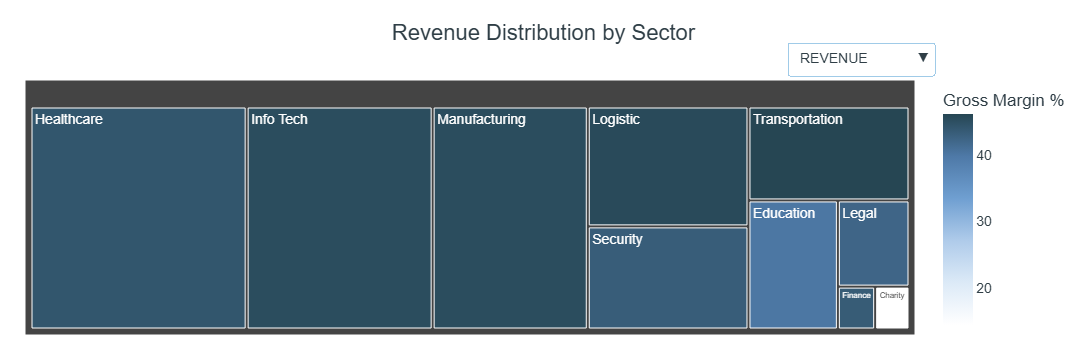

In [74]:
fig1 = create_treemap(df)
fig1.show()

The biggest customer base for the company in terms of revenue are the healthcare and infotech sectors. Gross profit and margins for finance and charity sectors are the lowest.

#### Chart 2 - scatter plot of average satisfaction to revenue+

In [75]:
import plotly.graph_objects as go

def create_scatter(df, metric="GROSS PROFIT"):     # Define as function to fit in plotly dash easily
    df = df.copy()
    df["AVERAGE SATISFACTION"] = (                 # Aggregate new metric, average survey score
        df["PRESALES AND PARTNERSHIP"] +
        df["TECHNICAL EXPERTISE"] +
        df["PROJECT DELIVERY"] +
        df["POST-SALES SUPPORT"]
    ) / 4
    client_df = (
        df.groupby(                           # Group by client type
            ["CLIENT ID","TYPE"],
            as_index=False
        )
        .agg({
            "REVENUE":"sum",                    # Get revenue, GP and new metric 
            "GROSS PROFIT":"sum",
            "AVERAGE SATISFACTION":"mean"
        })
    )
    plot_df = (
        client_df
        .replace([np.inf,-np.inf],np.nan)      # Remove possible null values
        .dropna(subset=[
            "AVERAGE SATISFACTION",
            "REVENUE",
            "GROSS PROFIT"
        ])
    )
    colour_map={                          # Set marker colors
        "Govt":COLORS["blue"],
        "Private":COLORS["teal"],
        "NPO":COLORS["light_blue"]
    }
    fig=go.Figure()
    client_types=list(plot_df["TYPE"].unique())       # Plot scatter of financial metric to avg satisfaction
    # Scatter Points
    for client_type in client_types:
        temp=plot_df[
            plot_df["TYPE"]==client_type
        ]

        fig.add_trace(
            go.Scatter(
                x=temp["AVERAGE SATISFACTION"],
                y=temp[metric],
                mode="markers",
                name=client_type,
                text=temp["CLIENT ID"],
                marker=dict(
                    size=12,
                    color=colour_map[client_type],
                    opacity=0.85,
                    line=dict(
                        color="white",
                        width=1
                    )
                ),
                hovertemplate=
                "<b>%{text}</b><br>"
                "Average Satisfaction: %{x:.2f}<br>"
                f"{metric.title().replace('_',' ')}: $%{{y:,.0f}}"
                "<extra></extra>"
            )
        )
    # Trend Lines
    trend_x=np.linspace(
        plot_df["AVERAGE SATISFACTION"].min(),
        plot_df["AVERAGE SATISFACTION"].max(),
        100
    )
    metrics=["REVENUE","GROSS PROFIT"]
    trend_lines={}
    for m in metrics:
        slope,intercept=np.polyfit(
            plot_df["AVERAGE SATISFACTION"],
            plot_df[m],
            1
        )
        trend_lines[m]=slope*trend_x+intercept
    fig.add_trace(
        go.Scatter(
            x=trend_x,
            y=trend_lines[metric],
            mode="lines",
            name="Trend",
            line=dict(
                color=COLORS["red"],
                width=3,
                dash="dash"
            ),
            hoverinfo="skip"
        )
    )
    # Dropdown button to switch between revenue and GP
    buttons=[]
    for m in metrics:
        y_values=[]
        hover=[]
        for client_type in client_types:
            temp=plot_df[
                plot_df["TYPE"]==client_type
            ]
            y_values.append(temp[m])
            hover.append(
                "<b>%{text}</b><br>"
                "Average Satisfaction: %{x:.2f}<br>"
                f"{m.replace('_',' ')}: $%{{y:,.0f}}"
                "<extra></extra>"
            )
        y_values.append(trend_lines[m])
        buttons.append(
            dict(
                label=m.replace("_"," ").title(),
                method="update",
                args=[
                    {
                        "y":y_values,
                        "hovertemplate":hover+["skip"]
                    },
                    {
                        "title":{
                            "text":f"Customer Satisfaction vs {m.replace('_',' ').title()}",
                            "x":0.5
                        },
                        "yaxis":{
                            "title":f"{m.replace('_',' ').title()} ($)"
                        }
                    }
                ]
            )
        )
    fig.update_layout(         # Set chart layouts
        title={ 
            "text":f"Customer Satisfaction vs {metric.replace('_',' ').title()}",
            "x":0.5,
            "font":{
                "size":22,
                "color":COLORS["text"]
            }
        },
        template="plotly_white",
        paper_bgcolor=COLORS["card"],
        plot_bgcolor="white",
        font=dict(
            family="Arial",
            size=14,
            color=COLORS["text"]
        ),
        height=550,
        margin=dict(
            t=80,
            l=60,
            r=40,
            b=50
        ),
        xaxis=dict(
            title="Average Satisfaction",
            gridcolor=COLORS["grid"]
        ),
        yaxis=dict(
            title="Gross Profit ($)",
            gridcolor=COLORS["grid"],
            tickprefix="$",
            separatethousands=True
        ),
        legend=dict(
            orientation="h",
            x=0.5,
            xanchor="center",
            y=1.08
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                x=1.02,
                y=1.15,
                bgcolor=COLORS["card"],
                bordercolor=COLORS["grid"],
                showactive=True
            )
        ]
    )
    return fig

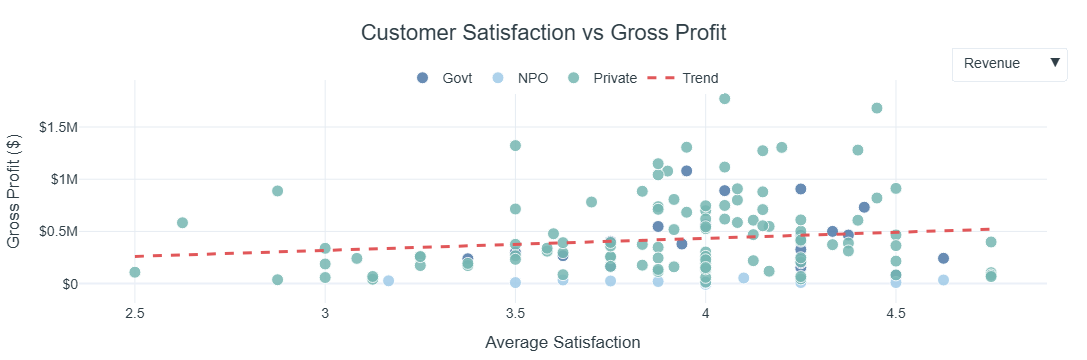

In [76]:
fig2 = create_scatter(df)
fig2.show()

There is a slight increasing trend in the gross profit by average customer satisfaction recorded using the surveys. This indicates that profitable customers are usually more satisified with the company's performance, increasing empahsis on these customer bases could bring in repeat customers.

#### Chart 3 - stacked bar chart of nps category by sector

In [77]:
import plotly.graph_objects as go

def create_nps(df):                   # Define as function to fit in plotly dash easily
    def prepare_data(data):           # Prepare data according to the selected region 
        nps = (
            data.groupby(["SECTOR", "NPS CATEGORY"])       # Group by sector and NPS category
            .size()
            .unstack(fill_value=0)
        )
        nps["Total"] = nps.sum(axis=1)
        nps = nps.sort_values("Total", ascending=False)
        nps = nps.drop(columns="Total")
        return nps
    all_df = prepare_data(df)        # Retrieves all data
    sg_df = prepare_data(            # Retrieves only SG-based company data
        df[
            df["SG-BASED"]
            .astype(str)
            .str.upper()
            .eq("Y")
        ]
    )
    overseas_df = prepare_data(     # Retrives only overseas company data
        df[
            ~df["SG-BASED"]
            .astype(str)
            .str.upper()
            .eq("Y")
        ]
    )
    colours = {   # set color scheme                 
        "Promoter": COLORS["blue"],
        "Passive": COLORS["light_blue"],
        "Detractor": "#BFC5CC"
    }
    categories = [     
        "Promoter",
        "Passive",
        "Detractor"
    ]
    fig = go.Figure()
    def add_traces(dataframe, visible):
        for category in categories:
            values = (
                dataframe[category]
                if category in dataframe.columns
                else [0] * len(dataframe.index)
            )
            fig.add_trace(
                go.Bar(
                    x=dataframe.index,
                    y=values,
                    name=category,
                    visible=visible,
                    marker_color=colours[category],
                    hovertemplate=
                    "<b>%{x}</b><br>"
                    f"{category}: "+"%{y}<extra></extra>"
                )
            )
    add_traces(all_df, True)               # Default view set to all data
    add_traces(sg_df, False)
    add_traces(overseas_df, False)
    n = len(categories)
    fig.update_layout(
        title={
            "text":"Customer Loyalty by Sector",
            "x":0.5,
            "font":{
                "size":22,
                "color":COLORS["text"]
            }
        },
        template="plotly_white",           # Set chart layouts
        barmode="stack",
        paper_bgcolor=COLORS["card"],
        plot_bgcolor="white",
        font=dict(
            family="Arial",
            size=14,
            color=COLORS["text"]
        ),
        height=550,
        margin=dict(
            t=120,
            l=60,
            r=40,
            b=70
        ),
        xaxis=dict(
            title="Sector",
            showgrid=False,
            linecolor=COLORS["grid"]
        ),
        yaxis=dict(
            title="Number of Clients",
            gridcolor=COLORS["grid"]
        ),
        legend=dict(
            orientation="h",
            x=0.5,
            xanchor="center",
            y=-0.30
        ),
        updatemenus=[           # Create buttons to update chart according to buttons selected 
            dict(
                type="buttons",
                direction="right",
                x=0.5,
                xanchor="center",
                y=1.08,
                bgcolor=COLORS["card"],
                bordercolor=COLORS["grid"],
                showactive=True,
                buttons=[
                    dict(
                        label="All",
                        method="update",
                        args=[
                            {
                                "visible":[True]*n+[False]*n+[False]*n      # All data (default)
                            },
                            {
                                "title":{
                                    "text":"Customer Loyalty by Sector",
                                    "x":0.5
                                }
                            }
                        ]
                    ),
                    dict(
                        label="Singapore",
                        method="update",
                        args=[
                            {
                                "visible":[False]*n+[True]*n+[False]*n
                            },
                            {
                                "title":{
                                    "text":"Customer Loyalty by Sector (Singapore)",     # Only SG-based
                                    "x":0.5
                                }
                            }
                        ]
                    ),
                    dict(
                        label="Overseas",
                        method="update",
                        args=[
                            {
                                "visible":[False]*n+[False]*n+[True]*n
                            },
                            {
                                "title":{
                                    "text":"Customer Loyalty by Sector (Overseas)",    # Only overseas based
                                    "x":0.5
                                }
                            }
                        ]
                    )
                ]
            )
        ]
    )
    return fig

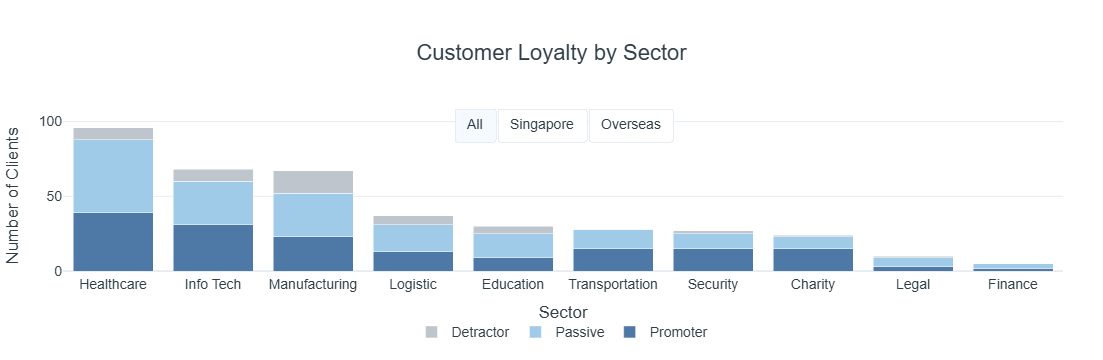

In [78]:
fig3 = create_nps(df)
fig3.show()

The NPS rating shows which customers from which sectors are more likely to request more of the company's services in the future.

Dashboard

In [79]:
# Individual dashboard 
from dash import Dash, html, dcc

app = Dash(__name__)

app.layout = html.Div(
    style={
        "backgroundColor": "#F4F6F9",    # Set color and font scheme
        "padding": "20px",
        "fontFamily": "Arial"
    },
    children=[
        html.Img(
            src="/assets/DAVI_company_logo.png",
            style={
                "height": "70px",
                "position": "absolute",
                "top": "20px",
                "left": "20px"
            }
        ),
        html.H1(
            "Customer Insights Dashboard",    # Title
            style={
                "textAlign": "center",
                "color": "#2C3E50"
            }
        ),
        html.P(
            "Interactive dashboard analysing revenue, profitability and customer satisfaction.",   # Dashboard description 
            style={
                "textAlign": "center",
                "fontSize": "18px",
                "marginBottom": "25px"
            }
        ),
        html.Div(
            style={
                "display": "flex",
                "justifyContent": "space-between",
                "marginBottom": "25px"
            },
            children=[
                html.Div([
                    html.Label("Year"),      # Dropdown selector for year
                    dcc.Dropdown(
                        id="year-dropdown",
                        options=[{"label":"All Years","value":"All"}] +
                        [{"label":str(y),"value":y} for y in sorted(df["YEAR"].unique())],
                        value="All",
                        clearable=False
                    )
                ], style={"width":"30%"}),
                html.Div([
                    html.Label("Client Type"),      # check boxes for client type
                    dcc.Checklist(
                        id="type-checklist",
                        options=[
                            {"label":"Govt","value":"Govt"},
                            {"label":"Private","value":"Private"},
                            {"label":"NPO","value":"NPO"}
                        ],
                        value=["Govt","Private","NPO"],
                        inline=True
                    )
                ], style={"width":"35%"}),

                html.Div([
                    html.Label("Sector"),    # Dropdown selector for sector
                    dcc.Dropdown(
                        id="sector-dropdown",
                        options=[{"label":"All Sectors","value":"All"}] +
                        [{"label":s,"value":s} for s in sorted(df["SECTOR"].unique())],
                        value="All",
                        clearable=False
                    )
                ], style={"width":"30%"})
            ]
        ),
        html.Div(
            dcc.Graph(id="treemap"),    # Graph 1 (treemap) 
            style={
                "backgroundColor":"white",
                "padding":"10px",
                "borderRadius":"10px",
                "boxShadow":"2px 2px 8px lightgrey",
                "marginBottom":"20px"
            }
        ),
        html.Div(
            style={
                "display":"flex",
                "justifyContent":"space-between"
            },
            children=[
                html.Div(
                    dcc.Graph(id="scatter"),    # Graph 2 (scatter plot)
                    style={
                        "width":"49%",
                        "backgroundColor":"white",
                        "padding":"10px",
                        "borderRadius":"10px",
                        "boxShadow":"2px 2px 8px lightgrey"
                    }
                ),

                html.Div(
                    dcc.Graph(id="nps"),   # Graph 3 (stacked bar)
                    style={
                        "width":"49%",
                        "backgroundColor":"white",
                        "padding":"10px",
                        "borderRadius":"10px",
                        "boxShadow":"2px 2px 8px lightgrey"
                    }
                )
            ]
        )
    ]
)

callbacks

In [80]:
from dash import Input, Output

@app.callback(
    Output("treemap", "figure"),       # Output for 3 charts
    Output("scatter", "figure"),
    Output("nps", "figure"),

    Input("year-dropdown", "value"),    # Input for metric selectors
    Input("type-checklist", "value"),   # Year, client type and sector
    Input("sector-dropdown", "value")
)

def update_dashboard(
    selected_year,
    selected_types,
    selected_sector
):
    dfcopy = df.copy()
    # Apply Filters
    if selected_year != "All":
        dfcopy = dfcopy[dfcopy["YEAR"] == selected_year]
    dfcopy = dfcopy[dfcopy["TYPE"].isin(selected_types)]
    if selected_sector != "All":
        dfcopy = dfcopy[dfcopy["SECTOR"] == selected_sector]
    # Create figures using defined functions
    treemap = create_treemap(dfcopy)
    scatter = create_scatter(dfcopy)
    nps = create_nps(dfcopy)

    return treemap, scatter, nps

In [81]:
if __name__ == "__main__":
    app.run(debug=True, port=5003)

---

#### Chart 1 - gross profit+ by client sector

In [3]:
import plotly.express as px

def create_chart1(filtered_df):
    metrics = ["REVENUE", "COGS", "GROSS PROFIT"]
    sector_data = {}
    for metric in metrics:
        sector_data[metric] = (
            filtered_df
            .groupby("SECTOR")[metric]
            .sum()
            .reset_index()
            .sort_values(metric, ascending=False)
        )
    default_metric = "GROSS PROFIT"
    fig = px.bar(
        sector_data[default_metric],
        x="SECTOR",
        y=default_metric,
        color=default_metric,
        text_auto=".2s",
        color_continuous_scale=[
            [0.00, "#FFFFFF"],
            [0.20, COLORS["light_blue"]],
            [0.50, COLORS["teal"]],
            [1.00, COLORS["blue"]]
        ],
        template="plotly_white"
    )
    buttons = []
    for metric in metrics:
        temp = sector_data[metric]
        buttons.append(
            dict(
                label=metric.replace("_", " "),
                method="update",
                args=[
                    {
                        "x":[temp["SECTOR"]],
                        "y":[temp[metric]],
                        "text":[temp[metric]],
                        "marker.color":[temp[metric]]
                    },
                    {
                        "title":{
                            "text":f"{metric.replace('_',' ').title()} by Client Sector",
                            "x":0.5,
                            "font":{
                                "size":22,
                                "color":COLORS["text"]
                            }
                        },
                        "yaxis.title":metric.replace("_"," ").title()
                    }
                ]
            )
        )
    fig.update_traces(
        textposition="outside",
        hovertemplate=
        "<b>Sector:</b> %{x}<br>"
        "<b>Value:</b> $%{y:,.0f}"
        "<extra></extra>"
    )
    fig.update_layout(
        title={
            "text":"Gross Profit by Client Sector",
            "x":0.5,
            "font":{
                "size":22,
                "color":COLORS["text"]
            }
        },
        template="plotly_white",
        paper_bgcolor=COLORS["card"],
        plot_bgcolor="white",
        font=dict(
            family="Arial",
            size=14,
            color=COLORS["text"]
        ),
        height=550,
        margin=dict(
            t=80,
            l=60,
            r=40,
            b=50
        ),
        xaxis=dict(
            title="Client Sector",
            tickangle=-25,
            gridcolor=COLORS["grid"]
        ),
        yaxis=dict(
            title="Gross Profit",
            tickprefix="$",
            separatethousands=True,
            gridcolor=COLORS["grid"]
        ),
        coloraxis_showscale=False,
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                x=1.02,
                y=1.15,
                showactive=True,
                bgcolor=COLORS["card"],
                bordercolor=COLORS["light_blue"],
                font=dict(color=COLORS["text"])
            )
        ]
    )
    return fig

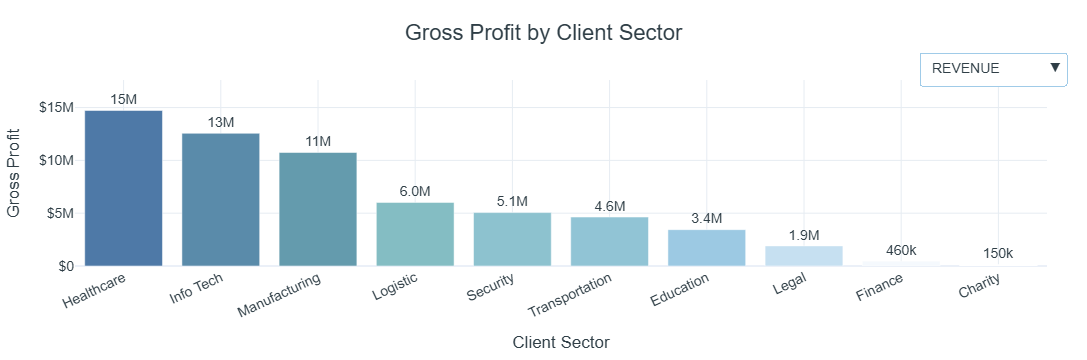

In [4]:
# Chart 1
fig1 = create_chart1(df)
fig1.show()

#### Chart 2 - revenue+ by year

In [5]:
import plotly.graph_objects as go

def create_chart2(filtered_df, metric="REVENUE"):
    yearly = (
        filtered_df
        .groupby("YEAR")[["REVENUE","COGS","GROSS PROFIT"]]
        .sum()
        .reset_index()
    )
    colour_map = {
        "REVENUE": COLORS["blue"],
        "COGS": COLORS["dark_teal"],
        "GROSS PROFIT": COLORS["light_blue"]
    }
    fig = go.Figure()
    fig.add_trace(
        go.Bar(
            x=yearly["YEAR"],
            y=yearly[metric],
            name=metric.replace("_"," "),
            marker_color=colour_map[metric],
            text=yearly[metric],
            texttemplate="$%{text:,.0f}",
            textposition="outside",
            hovertemplate=
            "<b>Year:</b> %{x}<br>"
            f"<b>{metric.replace('_',' ').title()}</b>: $%{{y:,.0f}}"
            "<extra></extra>"
        )
    )
    buttons = []
    for m in ["REVENUE","COGS","GROSS PROFIT"]:
        buttons.append(
            dict(
                label=m.replace("_"," "),
                method="update",
                args=[
                    {
                        "y":[yearly[m]],
                        "text":[yearly[m]],
                        "marker.color":[colour_map[m]],
                        "name":[m.replace("_"," ")]
                    },
                    {
                        "title":{
                            "text":f"{m.replace('_',' ').title()} by Year",
                            "x":0.5,
                            "font":{
                                "size":22,
                                "color":COLORS["text"]
                            }
                        },
                        "yaxis.title":f"{m.replace('_',' ').title()} ($)"
                    }
                ]
            )
        )
    fig.update_layout(
        title={
            "text":f"{metric.replace('_',' ').title()} by Year",
            "x":0.5,
            "font":{
                "size":22,
                "color":COLORS["text"]
            }
        },
        template="plotly_white",
        paper_bgcolor=COLORS["card"],
        plot_bgcolor="white",
        font=dict(
            family="Arial",
            size=14,
            color=COLORS["text"]
        ),
        height=550,
        margin=dict(
            t=80,
            l=60,
            r=40,
            b=50
        ),
        xaxis=dict(
            title="Year",
            showgrid=False,
            linecolor=COLORS["grid"]
        ),
        yaxis=dict(
            title="Revenue ($)",
            tickprefix="$",
            separatethousands=True,
            gridcolor=COLORS["grid"]
        ),
        hoverlabel=dict(
            bgcolor="white",
            font_size=13,
            font_family="Arial"
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                x=1.02,
                y=1.15,
                showactive=True,
                bgcolor=COLORS["card"],
                bordercolor=COLORS["light_blue"],
                font=dict(
                    color=COLORS["text"]
                )
            )
        ],
        showlegend=False
    )
    return fig

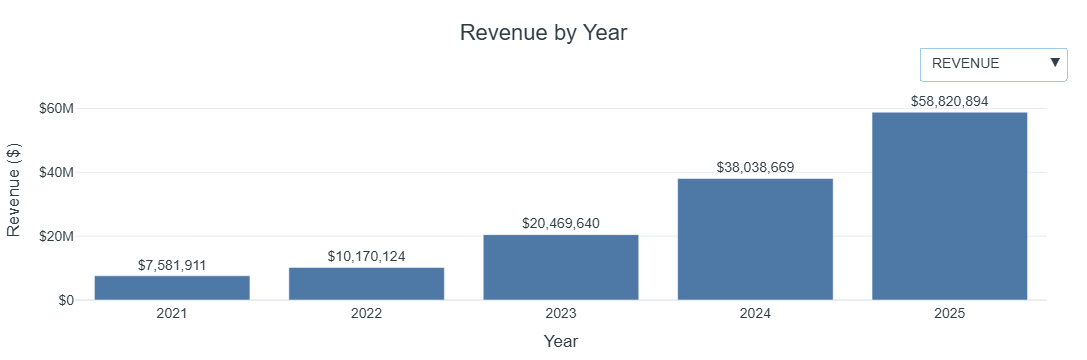

In [6]:
# Chart 2
fig2 = create_chart2(df)
fig2.show()

#### Chart 3 - average customer satisfaction

In [7]:
import plotly.graph_objects as go

def create_chart3(filtered_df):
    def get_ratings(data):
        return (
            data[
                [
                    "PRESALES AND PARTNERSHIP",
                    "TECHNICAL EXPERTISE",
                    "PROJECT DELIVERY",
                    "POST-SALES SUPPORT"
                ]
            ]
            .mean()
            .round(2)
        )
    categories = [
        "Presales",
        "Technical",
        "Project Delivery",
        "Post Sales"
    ]
    ratings = get_ratings(filtered_df)
    bar_colours = [
        COLORS["blue"],
        COLORS["teal"],
        COLORS["light_blue"],
        "grey"
    ]
    fig = go.Figure()
    fig.add_trace(
        go.Bar(
            x=categories,
            y=ratings.values,
            marker_color=bar_colours,
            text=ratings.values,
            texttemplate="%{text:.2f}",
            textposition="outside",
            hovertemplate=
            "<b>%{x}</b><br>"
            "Average Rating: %{y:.2f}"
            "<extra></extra>"
        )
    )
    buttons = []
    ratings_all = get_ratings(filtered_df)
    buttons.append(
        dict(
            label="All Years",
            method="update",
            args=[
                {
                    "y":[ratings_all.values],
                    "text":[ratings_all.values]
                },
                {
                    "title":{
                        "text":"Average Customer Satisfaction (All Years)",
                        "x":0.5,
                        "font":{
                            "size":22,
                            "color":COLORS["text"]
                        }
                    }
                }
            ]
        )
    )
    for year in sorted(filtered_df["YEAR"].unique()):
        temp = filtered_df[
            filtered_df["YEAR"] == year
        ]
        ratings_year = get_ratings(temp)
        buttons.append(
            dict(
                label=str(year),
                method="update",
                args=[
                    {
                        "y":[ratings_year.values],
                        "text":[ratings_year.values]
                    },
                    {
                        "title":{
                            "text":f"Average Customer Satisfaction ({year})",
                            "x":0.5,
                            "font":{
                                "size":22,
                                "color":COLORS["text"]
                            }
                        }
                    }
                ]
            )
        )
    fig.update_layout(
        title={
            "text":"Average Customer Satisfaction (All Years)",
            "x":0.5,
            "font":{
                "size":22,
                "color":COLORS["text"]
            }
        },
        template="plotly_white",
        paper_bgcolor=COLORS["card"],
        plot_bgcolor="white",
        font=dict(
            family="Arial",
            size=14,
            color=COLORS["text"]
        ),
        height=550,
        margin=dict(
            t=80,
            l=60,
            r=40,
            b=50
        ),
        xaxis=dict(
            title="Service Dimension",
            showgrid=False,
            linecolor=COLORS["grid"]
        ),
        yaxis=dict(
            title="Average Rating",
            range=[0,5],
            gridcolor=COLORS["grid"]
        ),
        hoverlabel=dict(
            bgcolor="white",
            font_size=13,
            font_family="Arial"
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                x=1.02,
                y=1.15,
                showactive=True,
                bgcolor=COLORS["card"],
                bordercolor=COLORS["light_blue"],
                font=dict(
                    color=COLORS["text"]
                )
            )
        ],
        showlegend=False
    )
    return fig

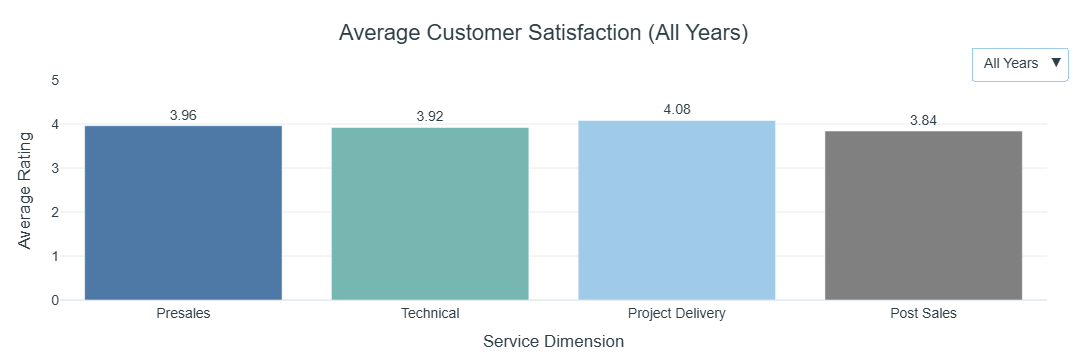

In [8]:
# Chart 3
fig3 = create_chart3(df)
fig3.show()

Dashboard

In [9]:
# Individual Dashboard 

# Create Dash App
app = Dash(__name__)
app.title = "IT Solutions Integrator Dashboard"

In [10]:
from dash import Dash, html, dcc

app = Dash(__name__)

app.layout = html.Div(
    style={
        "backgroundColor":"#F4F6F9",
        "padding":"20px",
        "fontFamily":"Arial"
    },
    children=[
        html.Img(
            src="/assets/DAVI_company_logo.png",
            style={
                "height": "70px",
                "position": "absolute",
                "top": "20px",
                "left": "20px"
            }
        ),
        # Header
        html.H1(
            "IT Solutions Integrator Performance Dashboard",
            style={
                "textAlign":"center",
                "color":"#2C3E50"
            }
        ),
        html.P(
            "Interactive dashboard analysing financial performance and customer satisfaction.",
            style={
                "textAlign":"center",
                "fontSize":"18px",
                "marginBottom":"25px"
            }
        ),
        # Filters
        html.Div(
            style={
                "display":"flex",
                "justifyContent":"space-between",
                "marginBottom":"25px"
            },
            children=[
                # Year
                html.Div([
                    html.Label("Year"),
                    dcc.Dropdown(
                        id="year_dropdown",
                        options=[{"label":"All Years","value":"ALL"}] +
                        [
                            {"label":str(y),"value":y}
                            for y in sorted(df["YEAR"].unique())
                        ],
                        value="ALL",
                        clearable=False
                    )
                ],style={"width":"30%"}),
                # Client Type
                html.Div([
                    html.Label("Client Type"),
                    dcc.Checklist(
                        id="type-checklist",
                        options=[
                            {
                                "label":t,
                                "value":t
                            }
                            for t in sorted(df["TYPE"].unique())
                        ],
                        value=list(df["TYPE"].unique()),
                        inline=True
                    )
                ],style={"width":"35%"}),
                # Sector
                html.Div([
                    html.Label("Sector"),
                    dcc.Dropdown(
                        id="sector_dropdown",
                        options=[{"label":"All Sectors","value":"ALL"}] +
                        [
                            {"label":s,"value":s}
                            for s in sorted(df["SECTOR"].unique())
                        ],
                        value="ALL",
                        clearable=False
                    )
                ],style={"width":"30%"})
            ]
        ),
        # Main Chart
        html.Div(
            dcc.Graph(id="chart1"),
            style={
                "backgroundColor":"white",
                "padding":"10px",
                "borderRadius":"10px",
                "boxShadow":"2px 2px 8px lightgrey",
                "marginBottom":"20px"
            }
        ),
        # Bottom Charts
        html.Div(

            style={
                "display":"flex",
                "justifyContent":"space-between"
            },
            children=[
                html.Div(
                    dcc.Graph(id="chart2"),
                    style={
                        "width":"49%",
                        "backgroundColor":"white",
                        "padding":"10px",
                        "borderRadius":"10px",
                        "boxShadow":"2px 2px 8px lightgrey"
                    }
                ),
                html.Div(
                    dcc.Graph(id="chart3"),
                    style={
                        "width":"49%",
                        "backgroundColor":"white",
                        "padding":"10px",
                        "borderRadius":"10px",
                        "boxShadow":"2px 2px 8px lightgrey"
                    }
                )
            ]
        )
    ]
)

Callbacks

In [11]:
from dash import Input, Output

@app.callback(
    Output("chart1","figure"),
    Output("chart2","figure"),
    Output("chart3","figure"),
    Input("year_dropdown","value"),
    Input("sector_dropdown","value"),
    Input("type-checklist","value")
)
def update_dashboard(selected_year, selected_sector, selected_types):
    filtered = df.copy()
    # Year filter
    if selected_year != "ALL":
        filtered = filtered[
            filtered["YEAR"] == selected_year
        ]
    # Sector filter
    if selected_sector != "ALL":
        filtered = filtered[
            filtered["SECTOR"] == selected_sector
        ]
    # Client Type filter
    if selected_types:
        filtered = filtered[
            filtered["TYPE"].isin(selected_types)
        ]
    fig1 = create_chart1(filtered)
    fig2 = create_chart2(filtered)
    fig3 = create_chart3(filtered)
    return fig1, fig2, fig3

In [12]:
# Run Dashboard
if __name__ == "__main__":
    app.run(
        debug=True,
        use_reloader=False,
        port=5002
    )

---

#### Chart 1 - client distribution by country

In [92]:
import pandas as pd
import plotly.express as px

def create_sunburst(df):
    df = df.copy()
    # Clean columns
    df.columns = df.columns.str.strip()
    df["NPS RATING"] = pd.to_numeric(
        df["NPS RATING"],
        errors="coerce"
    )
    df["YEAR"] = pd.to_numeric(
        df["YEAR"],
        errors="coerce"
    )
    df["NPS Category"] = pd.cut(
        df["NPS RATING"],
        bins=[-1,6,8,10],
        labels=[
            "Detractor",
            "Passive",
            "Promoter"
        ]
    )
    df["COUNTRY OF OVERSEAS CLIENT"] = (
        df["COUNTRY OF OVERSEAS CLIENT"]
        .fillna("Country Not Specified")
        .astype(str)
        .str.strip()
    )
    plot_df = (
        df.dropna(
            subset=[
                "NPS RATING",
                "NPS Category",
                "YEAR"
            ]
        )
        .copy()
    )
    plot_df["YEAR"] = plot_df["YEAR"].astype(int)
    plot_df["NPS Category"] = (
        plot_df["NPS Category"]
        .astype(str)
    )
    plot_df["SG-BASED"] = (
        plot_df["SG-BASED"]
        .astype(str)
        .str.strip()
        .str.upper()
    )
    plot_df["Client Location"] = plot_df["SG-BASED"].apply(
        lambda x: "Singapore"
        if x == "Y"
        else "Overseas"
    )
    plot_df["Country"] = plot_df.apply(
        lambda row:
        "Singapore"
        if row["SG-BASED"] == "Y"
        else row["COUNTRY OF OVERSEAS CLIENT"],
        axis=1
    )
    years = ["All Years"] + sorted(plot_df["YEAR"].unique())
    nps_filters = [
        "All Categories",
        "Detractor",
        "Passive",
        "Promoter"
    ]
    fig = None
    trace_info = []
    for year in years:
        for nps in nps_filters:
            temp = plot_df.copy()
            if year != "All Years":
                temp = temp[
                    temp["YEAR"] == year
                ]
            if nps != "All Categories":
                temp = temp[
                    temp["NPS Category"] == nps
                ]
            if temp.empty:
                continue
            sun = px.sunburst(
                temp,
                path=[
                    "Client Location",
                    "Country"
                ],
                color="Country",
                color_discrete_sequence=[
                    "#ADE8F4",
                    "#90E0EF",
                    "#48CAE4",
                    "#00B4D8",
                    "#0096C7",
                    "#0077B6",
                    "#023E8A",
                    "#03045E"
                ]
            )
            if fig is None:
                fig = sun
                fig.data[0].visible = True

            else:
                sun.data[0].visible = False
                fig.add_trace(sun.data[0])
            trace_info.append(
                {
                    "year":year,
                    "nps":nps
                }
            )
    year_buttons = []
    for year in years:
        visibility = [
            t["year"] == year and
            t["nps"] == "All Categories"
            for t in trace_info
        ]
        label = (
            "All Years"
            if year == "All Years"
            else str(year)
        )
        year_buttons.append(
            dict(
                label=label,
                method="update",
                args=[
                    {
                        "visible":visibility
                    },
                    {
                        "title":{
                            "text":
                            "Client Distribution by Country"
                            f"<br><sup>{label} — All NPS Categories</sup>",
                            "x":0.5
                        }
                    }
                ]
            )
        )
    nps_buttons = []
    for nps in nps_filters:
        visibility = [
            t["year"] == "All Years" and
            t["nps"] == nps
            for t in trace_info
        ]
        nps_buttons.append(
            dict(
                label=nps,
                method="update",
                args=[
                    {
                        "visible":visibility
                    },
                    {
                        "title":{
                            "text":
                            "Client Distribution by Country"
                            f"<br><sup>All Years — {nps}</sup>",
                            "x":0.5
                        }
                    }
                ]
            )
        )
    fig.update_traces(
        branchvalues="total",
        textinfo="label+percent parent",
        marker=dict(
            line=dict(
                color="white",
                width=2
            )
        ),
        hovertemplate=
        "<b>%{label}</b><br>"
        "Number of Clients: %{value}<br>"
        "Percentage: %{percentParent:.1%}"
        "<extra></extra>"
    )
    fig.update_layout(
        title={
            "text":
            "Client Distribution by Country"
            "<br><sup>Filter the countries using NPS Category</sup>",
            "x":0.5,
            "y":0.89,
            "font":{
                "size":26
            }
        },
        height=600,
        font=dict(
            family="Arial",
            color="#023047"
        ),
        margin=dict(
            t=230,
            l=50,
            r=50,
            b=50
        ),
        annotations=[
            dict(
                text="<b>Select Year</b>",
                x=0.08,
                y=1.15,
                xref="paper",
                yref="paper",
                showarrow=False,
                xanchor="left",
                font=dict(
                    size=15,
                    color="#023E8A"
                )
            ),
            dict(
                text="<b>Select NPS Category</b>",
                x=0.55,
                y=1.20,
                xref="paper",
                yref="paper",
                showarrow=False,
                xanchor="left",
                font=dict(
                    size=15,
                    color="#023E8A"
                )
            )
        ],
        updatemenus=[
            dict(
                type="dropdown",
                buttons=year_buttons,
                direction="down",
                x=0.18,
                y=1.09,
                bgcolor="#E6F8FC",
                bordercolor="#00B4D8",
                borderwidth=2,
                showactive=True
            ),
            dict(
                type="buttons",
                buttons=nps_buttons,
                direction="right",
                x=0.85,
                y=1.13,
                bgcolor="#E6F8FC",
                bordercolor="#0077B6",
                borderwidth=2,
                showactive=True
            )
        ]
    )
    return fig

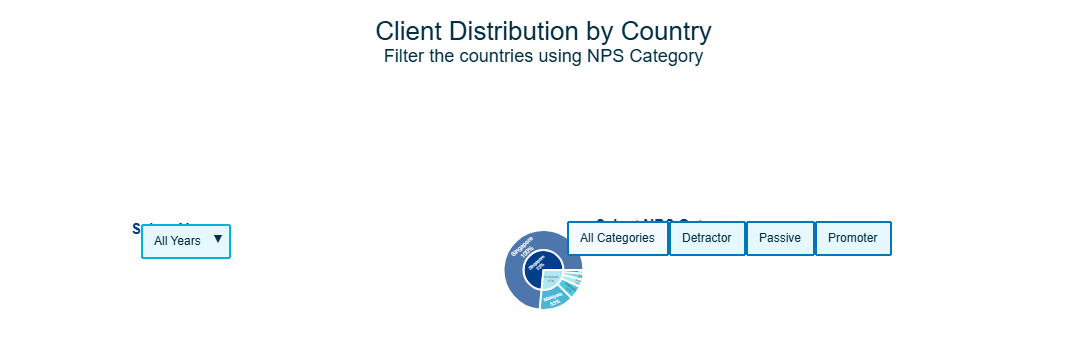

In [93]:
fig1 = create_sunburst(df)
fig1.show()

#### Chart 2 - revenue distrubtion by nps category

In [94]:
import plotly.graph_objects as go
import pandas as pd

def create_revenue_box(df):
    plot_df = df.copy()
    plot_df["CLIENT LOCATION"] = plot_df["SG-BASED"].apply(
        lambda value: "Singapore"
        if str(value).strip().upper() == "Y"
        else "Overseas"
    )
    category_order = [
        "Detractor",
        "Passive",
        "Promoter"
    ]
    category_colours = {
        "Detractor": "#ADE8F4",
        "Passive": "#00B4D8",
        "Promoter": "#0077B6"
    }
    location_filters = [
        "All Clients",
        "Singapore",
        "Overseas"
    ]
    size_filters = [
        "All Sizes",
        "1 ~ 49",
        "50 ~ 200",
        "> 200"
    ]
    fig = go.Figure()
    trace_information = []
    # LOCATION FILTER TRACES
    for location_filter in location_filters:
        if location_filter == "All Clients":
            filtered_df = plot_df.copy()
        else:
            filtered_df = plot_df[
                plot_df["CLIENT LOCATION"] == location_filter
            ]
        visible = (location_filter == "All Clients")
        for category in category_order:
            revenue_values = filtered_df.loc[
                filtered_df["NPS CATEGORY"] == category,
                "REVENUE"
            ]
            fig.add_trace(
                go.Box(
                    y=revenue_values,
                    name=category,
                    boxpoints="outliers",
                    boxmean=False,
                    notched=False,
                    marker=dict(
                        color=category_colours[category],
                        size=7
                    ),
                    line=dict(
                        color=category_colours[category],
                        width=3
                    ),
                    fillcolor=category_colours[category],
                    opacity=0.75,
                    hovertemplate=
                    f"<b>{category}</b><br>"
                    "Revenue: $%{y:,.0f}<br>"
                    f"Location: {location_filter}"
                    "<extra></extra>",
                    visible=visible,
                    showlegend=False
                )
            )
            trace_information.append({
                "filter_type":"location",
                "filter_value":location_filter
            })
            if revenue_values.empty:
                median_value = None
                median_text = ""
            else:
                median_value = revenue_values.median()
                median_text = f"Median: ${median_value:,.0f}"
            fig.add_trace(
                go.Scatter(
                    x=[category],
                    y=[median_value],
                    mode="markers+text",
                    marker=dict(
                        size=15,
                        symbol="diamond",
                        color="white",
                        line=dict(
                            color="#001D3D",
                            width=3
                        )
                    ),
                    text=[median_text],
                    textposition="top center",
                    textfont=dict(
                        size=14,
                        color="#001D3D"
                    ),
                    hovertemplate=
                    f"<b>{category}</b><br>"
                    f"{median_text}"
                    "<extra></extra>",
                    visible=visible,
                    showlegend=False
                )
            )
            trace_information.append({
                "filter_type":"location",
                "filter_value":location_filter
            })
    # STAFF SIZE FILTER TRACES
    for size_filter in size_filters:
        if size_filter == "All Sizes":
            filtered_df = plot_df.copy()
        else:
            filtered_df = plot_df[
                plot_df["STAFF STRENGTH"] == size_filter
            ]
        for category in category_order:
            revenue_values = filtered_df.loc[
                filtered_df["NPS CATEGORY"] == category,
                "REVENUE"
            ]
            fig.add_trace(
                go.Box(
                    y=revenue_values,
                    name=category,
                    boxpoints="outliers",
                    boxmean=False,
                    notched=False,
                    marker=dict(
                        color=category_colours[category],
                        size=7
                    ),
                    line=dict(
                        color=category_colours[category],
                        width=3
                    ),
                    fillcolor=category_colours[category],
                    opacity=0.75,
                    hovertemplate=
                    f"<b>{category}</b><br>"
                    "Revenue: $%{y:,.0f}<br>"
                    f"Staff Strength: {size_filter}"
                    "<extra></extra>",
                    visible=False,
                    showlegend=False
                )
            )
            trace_information.append({
                "filter_type":"size",
                "filter_value":size_filter
            })
            if revenue_values.empty:
                median_value = None
                median_text = ""
            else:
                median_value = revenue_values.median()
                median_text = f"Median: ${median_value:,.0f}"
            fig.add_trace(
                go.Scatter(
                    x=[category],
                    y=[median_value],
                    mode="markers+text",
                    marker=dict(
                        size=15,
                        symbol="diamond",
                        color="white",
                        line=dict(
                            color="#001D3D",
                            width=3
                        )
                    ),
                    text=[median_text],
                    textposition="top center",
                    textfont=dict(
                        size=14,
                        color="#001D3D"
                    ),
                    hovertemplate=
                    f"<b>{category}</b><br>"
                    f"{median_text}"
                    "<extra></extra>",
                    visible=False,
                    showlegend=False
                )
            )
            trace_information.append({
                "filter_type":"size",
                "filter_value":size_filter
            })
    # DROPDOWN BUTTONS
    location_buttons = []
    for location_filter in location_filters:
        visibility = [
            trace["filter_type"] == "location"
            and trace["filter_value"] == location_filter
            for trace in trace_information
        ]
        location_buttons.append(
            dict(
                label=location_filter,
                method="update",
                args=[
                    {"visible":visibility},
                    {"title":{
                        "text":"Revenue Distribution by NPS Category"
                               f"<br><sup>Location: {location_filter}</sup>",
                        "x":0.5
                    }}
                ]
            )
        )
    size_buttons = []
    for size_filter in size_filters:
        visibility = [
            trace["filter_type"] == "size"
            and trace["filter_value"] == size_filter
            for trace in trace_information
        ]
        size_buttons.append(
            dict(
                label=size_filter,
                method="update",
                args=[
                    {"visible":visibility},
                    {"title":{
                        "text":"Revenue Distribution by NPS Category"
                               f"<br><sup>Staff Strength: {size_filter}</sup>",
                        "x":0.5
                    }}
                ]
            )
        )
    # LAYOUT
    fig.update_layout(
        title={
            "text":"Revenue Distribution by NPS Category<br><sup>All Clients</sup>",
            "x":0.5,
            "font":{
                "size":26,
                "color":"#001D3D"
            }
        },
        xaxis_title="NPS Category",
        yaxis_title="Revenue ($)",
        xaxis=dict(
            categoryorder="array",
            categoryarray=category_order
        ),
        yaxis=dict(
            tickprefix="$",
            tickformat=",",
            gridcolor="#D9EAF2",
            zeroline=False
        ),
        height=600,
        template="plotly_white",
        showlegend=False,
        plot_bgcolor="white",
        margin=dict(
            l=90,
            r=100,
            t=210,
            b=90
        ),
        updatemenus=[
            dict(
                type="dropdown",
                buttons=location_buttons,
                active=0,
                x=0.03,
                y=1.12,
                direction="down",
                showactive=True,
                bgcolor="#E6F8FC",
                bordercolor="#00B4D8",
                borderwidth=2,
                font=dict(size=16)
            ),
            dict(
                type="dropdown",
                buttons=size_buttons,
                active=0,
                x=0.35,
                y=1.12,
                direction="down",
                showactive=True,
                bgcolor="#E6F8FC",
                bordercolor="#00B4D8",
                borderwidth=2,
                font=dict(size=16)
            )
        ]
    )
    return fig

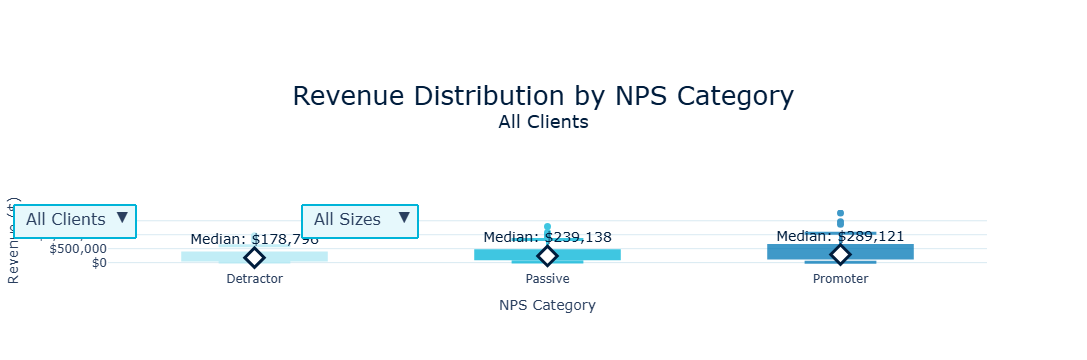

In [95]:
fig2 = create_revenue_box(df)
fig2.show()

#### Chart 3 - Average COGS Over Time by NPS Category

In [96]:
import pandas as pd
import plotly.graph_objects as go

def create_cogs_line(df):
    plot_df = df.copy()
    plot_df.columns = plot_df.columns.str.strip()
    numeric_columns = [
        "YEAR",
        "COGS",
        "MANPOWER"
    ]
    for column in numeric_columns:
        plot_df[column] = pd.to_numeric(
            plot_df[column],
            errors="coerce"
        )
    plot_df = plot_df.dropna(
        subset=[
            "YEAR",
            "COGS",
            "MANPOWER",
            "NPS CATEGORY"
        ]
    ).copy()
    plot_df["MANPOWER RANGE"] = pd.cut(
        plot_df["MANPOWER"],
        bins=[
            0,
            50000,
            100000,
            float("inf")
        ],
        labels=[
            "Below 50,000",
            "50,000 - 99,999",
            "100,000 and above"
        ],
        right=False
    )
    category_order = [
        "Detractor",
        "Passive",
        "Promoter"
    ]
    category_colours = {
        "Detractor": "#8ECAE6",
        "Passive": "#219EBC",
        "Promoter": "#023047"
    }
    manpower_filters = [
        "All Manpower Amounts",
        "Below 50,000",
        "50,000 - 99,999",
        "100,000 and above"
    ]
    fig = go.Figure()
    trace_information = []
    for manpower_filter in manpower_filters:
        if manpower_filter == "All Manpower Amounts":
            filtered_df = plot_df.copy()
        else:
            filtered_df = plot_df[
                plot_df["MANPOWER RANGE"].astype(str)
                == manpower_filter
            ].copy()
        yearly_cogs = (
            filtered_df
            .groupby(
                [
                    "YEAR",
                    "NPS CATEGORY"
                ],
                observed=True
            )["COGS"]
            .mean()
            .reset_index()
        )
        is_visible = (
            manpower_filter == "All Manpower Amounts"
        )
        for category in category_order:
            category_data = (
                yearly_cogs[
                    yearly_cogs["NPS CATEGORY"].astype(str)
                    == category
                ]
                .sort_values("YEAR")
            )
            fig.add_trace(
                go.Scatter(
                    x=category_data["YEAR"],
                    y=category_data["COGS"],
                    mode="lines+markers",
                    name=category,
                    line=dict(
                        color=category_colours[category],
                        width=3
                    ),
                    marker=dict(
                        color=category_colours[category],
                        size=8
                    ),
                    hovertemplate=(
                        f"<b>{category}</b><br>"
                        f"Manpower Amount: {manpower_filter}<br>"
                        "Year: %{x:.0f}<br>"
                        "Average COGS: $%{y:,.0f}"
                        "<extra></extra>"
                    ),
                    visible=is_visible,
                    showlegend=is_visible
                )
            )
            trace_information.append(
                {
                    "manpower_filter": manpower_filter,
                    "category": category
                }
            )
    manpower_buttons = []
    for manpower_filter in manpower_filters:
        visibility = [
            trace["manpower_filter"] == manpower_filter
            for trace in trace_information
        ]
        manpower_buttons.append(
            dict(
                label=manpower_filter,
                method="update",
                args=[
                    {
                        "visible": visibility,
                        "showlegend": visibility
                    },
                    {
                        "title": {
                            "text": (
                                "Average COGS Over Time by NPS Category"
                                "<br><sup>"
                                f"Manpower Amount: {manpower_filter}"
                                "</sup>"
                            ),
                            "x": 0.5,
                            "xanchor": "center"
                        }
                    }
                ]
            )
        )
    fig.update_layout(
        title={
            "text": (
                "Average COGS Over Time by NPS Category"
                "<br><sup>"
                "Manpower Amount: All Manpower Amounts"
                "</sup>"
            ),
            "x": 0.5,
            "xanchor": "center",
            "font": {
                "size": 24
            }
        },
        template="plotly_white",
        xaxis_title="Year",
        yaxis_title="Average COGS ($)",
        xaxis=dict(
            tickmode="linear",
            dtick=1,
            title_font=dict(size=16),
            tickfont=dict(size=12),
            gridcolor="#EDF2F7"
        ),
        yaxis=dict(
            title_font=dict(size=16),
            tickfont=dict(size=12),
            tickprefix="$",
            tickformat=",",
            gridcolor="#D9EAF2"
        ),
        legend=dict(
            title="NPS Category",
            font=dict(size=11)
        ),
        margin=dict(
            l=80,
            r=40,
            t=160,
            b=70
        ),
        annotations=[
            dict(
                text="<b>Select Manpower Amount</b>",
                x=0.02,
                y=1.20,
                xref="paper",
                yref="paper",
                showarrow=False,
                xanchor="left",
                font=dict(size=15)
            )
        ],
        updatemenus=[
            dict(
                type="dropdown",
                buttons=manpower_buttons,
                active=0,
                x=0.02,
                y=1.05,
                xanchor="left",
                yanchor="top",
                direction="down",
                showactive=True,
                bgcolor="#E6F8FC",
                bordercolor="#219EBC",
                borderwidth=3,
                font=dict(size=13),
                pad=dict(
                    r=15,
                    t=5
                )
            )
        ]
    )
    return fig

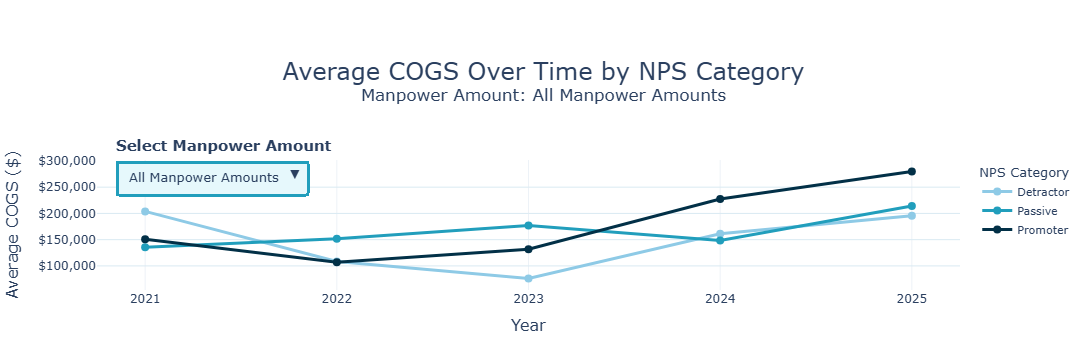

In [97]:
fig3 = create_cogs_line(df)
fig3.show()

Dashboard

In [98]:
# Individual Dashboard 
from dash import Dash, html, dcc

app = Dash(__name__)

app.layout = html.Div(
    style={
        "backgroundColor":"#F4F6F9",
        "padding":"20px",
        "fontFamily":"Arial"
    },
    children=[
        html.Img(
            src="/assets/DAVI_company_logo.png",
            style={
                "height": "70px",
                "position": "absolute",
                "top": "20px",
                "left": "20px"
            }
        ),
        # Header
        html.H1(
            "Financial Performance Dashboard",
            style={
                "textAlign":"center",
                "color":"#2C3E50"
            }
        ),
        html.P(
            "Interactive dashboard analysing revenue, cost and profitability.",
            style={
                "textAlign":"center",
                "fontSize":"18px",
                "marginBottom":"25px"
            }
        ),
        # Filters
        html.Div(

            style={
                "display":"flex",
                "justifyContent":"space-between",
                "marginBottom":"25px"
            },

            children=[
                # Year
                html.Div([

                    html.Label("Year"),

                    dcc.Dropdown(
                        id="year-dropdown",
                        options=[{"label":"All Years","value":"All"}] +
                        [{"label":str(y),"value":y}
                         for y in sorted(df["YEAR"].unique())],
                        value="All",
                        clearable=False
                    )

                ],style={"width":"30%"}),
                # Client Type
                html.Div([
                    html.Label("Client Type"),
                    dcc.Checklist(
                        id="type-checklist",
                        options=[
                            {"label":t,"value":t}
                            for t in sorted(df["TYPE"].unique())
                        ],
                        value=list(df["TYPE"].unique()),
                        inline=True
                    )
                ],style={"width":"35%"}),
                # Sector
                html.Div([
                    html.Label("Sector"),
                    dcc.Dropdown(
                        id="sector-dropdown",
                        options=[{"label":"All Sectors","value":"All"}] +
                        [{"label":s,"value":s}
                         for s in sorted(df["SECTOR"].unique())],
                        value="All",
                        clearable=False
                    )
                ],style={"width":"30%"})
            ]
        ),
        # Top Chart
        html.Div(
            dcc.Graph(id="cogs-line"),
            style={
                "backgroundColor":"white",
                "padding":"10px",
                "borderRadius":"10px",
                "boxShadow":"2px 2px 8px lightgrey",
                "marginBottom":"20px"
            }
        ),
        # Bottom Charts
        html.Div(
            style={
                "display":"flex",
                "justifyContent":"space-between"
            },
            children=[
                html.Div(
                    dcc.Graph(id="sunburst"),
                    style={
                        "width":"49%",
                        "backgroundColor":"white",
                        "padding":"10px",
                        "borderRadius":"10px",
                        "boxShadow":"2px 2px 8px lightgrey"
                    }
                ),
                html.Div(
                    dcc.Graph(id="revenue-box"),
                    style={
                        "width":"49%",
                        "backgroundColor":"white",
                        "padding":"10px",
                        "borderRadius":"10px",
                        "boxShadow":"2px 2px 8px lightgrey"
                    }
                )
            ]
        )
    ]
)

Callbacks

In [99]:
from dash import Input, Output

@app.callback(
    Output("cogs-line","figure"),
    Output("sunburst","figure"),
    Output("revenue-box","figure"),
    Input("year-dropdown","value"),
    Input("sector-dropdown","value"),
    Input("type-checklist","value")
)
def update_dashboard(selected_year, selected_sector, selected_types):
    filtered = df.copy()
    if selected_year != "All":
        filtered = filtered[filtered["YEAR"] == selected_year]
    if selected_sector != "All":
        filtered = filtered[filtered["SECTOR"] == selected_sector]
    if selected_types:
        filtered = filtered[
            filtered["TYPE"].isin(selected_types)
        ]
    fig1 = create_cogs_line(filtered)
    fig2 = create_sunburst(filtered)
    fig3 = create_revenue_box(filtered)
    return fig1, fig2, fig3

In [100]:
if __name__ == "__main__":
    app.run(debug=True, port=5001, suppress_callback_exceptions=True)

---

## Final Storyboard

#### Dashboard layout

In [101]:
from dash import Dash, html, dcc

app = Dash(__name__)

CARD_STYLE = {
    "backgroundColor": COLORS["card"],
    "padding": "15px",
    "borderRadius": "12px",
    "boxShadow": "0px 4px 12px rgba(0,0,0,0.10)",
    "border": f"1px solid {COLORS['grid']}"
}

app.layout = html.Div(
    style={
        "backgroundColor": COLORS["background"],
        "padding": "20px",
        "fontFamily": "Arial"
    },
    
    children=[
        html.Img(
            src="/assets/DAVI_company_logo.png",
            style={
                "height": "70px",
                "position": "absolute",
                "top": "20px",
                "left": "20px"
            }
        ),
        # Header
        html.H1(
            "IT Solutions Integrator Dashboard",
            style={
                "textAlign":"center",
                "color":COLORS["text"],
                "marginBottom":"5px"
            }
        ),

        html.H4(
            "Business Performance • Financial Analysis • Customer Insights",
            style={
                "textAlign":"center",
                "color":COLORS["teal"],
                "marginBottom":"30px"
            }
        ),

        # Filters
        html.Div(
            style={
                "display":"flex",
                "gap":"20px",
                "marginBottom":"25px",
                "alignItems":"center"
            },
            children=[
                html.Div(
                    children=[
                        html.Label("Year"),
                        dcc.Dropdown(
                            id="year-dropdown",
                            options=[{"label":"All","value":"All"}] +
                                    [{"label":str(y),"value":y}
                                     for y in sorted(df["YEAR"].unique())],
                            value="All",
                            clearable=False
                        )
                    ],
                    style={"width":"25%"}
                ),
                html.Div(
                    children=[
                        html.Label("Sector"),
                        dcc.Dropdown(
                            id="sector-dropdown",
                            options=[{"label":"All","value":"All"}] +
                                    [{"label":s,"value":s}
                                     for s in sorted(df["SECTOR"].unique())],
                            value="All",
                            clearable=False
                        )
                    ],
                    style={"width":"35%"}
                ),
                html.Div(
                    children=[
                        html.Label("Client Type"),
                        dcc.Checklist(
                            id="type-checklist",
                            options=[
                                {"label":t,"value":t}
                                for t in sorted(df["TYPE"].unique())
                            ],
                            value=list(df["TYPE"].unique()),
                            inline=True
                        )
                    ],
                    style={"width":"40%"}
                )
            ]
        ),
        
        # Storyboard Tabs
        dcc.Tabs(
            id="dashboard-tabs",
            value="overview",
            colors={
                "border": COLORS["grid"],
                "primary": COLORS["teal"],
                "background": COLORS["card"]
            },
            children=[
                dcc.Tab(
                    label="Business Overview",
                    value="overview"
                ),
                dcc.Tab(
                    label="Financial Performance",
                    value="financial"
                ),
                dcc.Tab(
                    label="Customer Insights",
                    value="customer"
                )
            ]
        ),
        html.Br(),
        # Dashboard Placeholder
        html.Div(
            id="dashboard-content"
        )
    ]
)

#### Dashboard callbacks

In [102]:
from dash import Input, Output

@app.callback(
    Output("dashboard-content","children"),

    Input("dashboard-tabs","value"),
    Input("year-dropdown","value"),
    Input("sector-dropdown","value"),
    Input("type-checklist","value")
)

def render_dashboard(
    tab,
    selected_year,
    selected_sector,
    selected_types
):
    dfcopy = df.copy()
    
    if selected_year != "All":
        dfcopy = dfcopy[dfcopy["YEAR"] == selected_year]

    if selected_sector != "All":
        dfcopy = dfcopy[dfcopy["SECTOR"] == selected_sector]

    dfcopy = dfcopy[
        dfcopy["TYPE"].isin(selected_types)
    ]

    # Business Overview
    if tab == "overview":
        return html.Div([
            html.H2(
                "Business Overview",
                style={
                    "color": COLORS["blue"],
                    "marginBottom": "20px"
                }
            ),

            html.Div(
                dcc.Graph(
                    figure=create_chart1(dfcopy),
                    config={"displayModeBar": False}
                ),
                style=CARD_STYLE
            ),

            html.Br(),
            
            html.Div(
                style={
                    "display": "flex",
                    "gap": "20px"
                },
                children=[
                    html.Div(
                        dcc.Graph(
                            figure=create_chart2(dfcopy),
                            config={"displayModeBar": False}
                        ),
                        style={
                            **CARD_STYLE,
                            "flex": 1
                        }
                    ),
                    html.Div(
                        dcc.Graph(
                            figure=create_chart3(dfcopy),
                            config={"displayModeBar": False}
                        ),
                        style={
                            **CARD_STYLE,
                            "flex": 1
                        }
                    )
                ]
            )
        ])
        
    # Financial Performance
    elif tab == "financial":
        return html.Div([
            html.H2(
                "Financial Performance",
                style={
                    "color": COLORS["blue"],
                    "marginBottom": "20px"
                }
            ),

            html.Div(
                dcc.Graph(
                    figure=create_cogs_line(dfcopy),
                    config={"displayModeBar": False}
                ),
                style=CARD_STYLE
            ),

            html.Br(),

            html.Div(
                style={
                    "display": "flex",
                    "gap": "20px"
                },
                children=[
                    html.Div(
                        dcc.Graph(
                            figure=create_sunburst(dfcopy),
                            config={"displayModeBar": False}
                        ),
                        style={
                            **CARD_STYLE,
                            "flex": 1
                        }
                    ),
                    html.Div(
                        dcc.Graph(
                            figure=create_revenue_box(dfcopy),
                            config={"displayModeBar": False}
                        ),
                        style={
                            **CARD_STYLE,
                            "flex": 1
                        }
                    )
                ]
            )
        ])
        
    # Customer Insights
    else:
        return html.Div([
            html.H2(
                "Customer Insights",
                style={
                    "color": COLORS["blue"],
                    "marginBottom": "20px"
                }
            ),
            
            html.Div(
                dcc.Graph(
                    figure=create_treemap(dfcopy),
                    config={"displayModeBar": False}
                ),
                style=CARD_STYLE
            ),

            html.Br(),

            html.Div(

                style={
                    "display": "flex",
                    "gap": "20px"
                },
                children=[
                    html.Div(
                        dcc.Graph(
                            figure=create_scatter(dfcopy),
                            config={"displayModeBar": False}
                        ),
                        style={
                            **CARD_STYLE,
                            "flex": 1
                        }
                    ),
                    html.Div(
                        dcc.Graph(
                            figure=create_nps(dfcopy),
                            config={"displayModeBar": False}
                        ),
                        style={
                            **CARD_STYLE,
                            "flex": 1
                        }
                    )
                ]
            )
        ])

#### Start dashboard

In [103]:
if __name__ == "__main__":
    app.run(debug=True, port=5000, suppress_callback_exceptions=True)

---